# Этап 1 (п. 1.1 плана). Граф переходов: вариант «без OldCase»

Ноутбук строит граф переходов между типами преступлений по таблице этапа 0 `compas_custody_charges.csv` шаг за шагом: эпизоды → журнал событий PM4Py → матрица переходов → графы (DFG, Heuristics Miner, Inductive Miner) → от чего зависит следующее состояние. После каждого важного шага числа сверяются с сохранёнными результатами варианта (`results`).

**Правило этого варианта.** Старые обвинения в смешанном эпизоде не учитываются (как в OldCase), а эпизоды **только из старых дел убираются из последовательности целиком**: состояния `OldCase` нет, событие = новое преступление. Этот ноутбук — ноутбук от 09.10 (`D:\diploma\claude\091026\stage1_nooldcase\jyp lab`), переделанный под таблицу этапа 0 и общий формат папок `stage1/`.

**Варианты работы с повторными заключениями** (у каждого своя папка в `stage1/`):
| Вариант (папка) | Обвинение по старому делу в смешанном эпизоде | Эпизод только из старых дел |
|---|---|---|
| все новые (`stage1/all_new`) | считается как новое | состояние = типы его обвинений |
| OldCase (`stage1/oldcase`, главный) | не учитывается | отдельное состояние `OldCase` |
| без OldCase (`stage1/no_oldcase`) | не учитывается | эпизод убран из последовательности |
| склейка ±7 (`stage1/glue7`) | как «все новые» или «без OldCase» (флаг) | сначала склейка соседних заключений ≤ 7 дней с общей статьёй |
| категории ×2 (`stage1/oldcase_x2`, отдельная ветка) | — | состояние `OldCase: <тип>` |

*Старое обвинение* — его `case_number` уже встречался у этого же человека (`id`) в более раннем эпизоде.

**Общее для всех вариантов:** объект = человек (`id`), событие = заключение (custody), состояние = множество из 15 типов преступлений (несколько типов — развилка), перевод jail → prison в тот же день склеивается с предыдущим заключением, Justice идёт отдельным шагом после остальных типов эпизода, терминального состояния нет (последний эпизод человека цензурируется концом наблюдения 19.04.2016), модели учатся на 80% людей и проверяются на 20% (seed 42).

**Как запустить.** В PowerShell: `D:\Git\diploma\.venv\Scripts\activate`, затем `jupyter lab` в папке `D:\diploma\jupyter lab`, открыть `stage1/no_oldcase/stage1_no_oldcase.ipynb`, *Run → Run All Cells* (около минуты). Ноутбук **не перезаписывает** сохранённые результаты: всё пересчитанное он пишет в `notebook_out/`.

## Шаг 0. Настройки

- `DATA` — входная таблица этапа 0 (её строит ноутбук `stage0 - data/build_compas_custody_charges.ipynb`);
- `RES` — сохранённые результаты варианта, с ними сверяется пересчёт;
- `OUT` — папка, куда ноутбук пишет то, что пересчитал (`notebook_out/`);
- `RUN_MODELS` — строить сети Петри (IM, HM, DFG) на train, меньше минуты;
- `RUN_EVAL` — пересчитать fitness/precision для HM dep 0.9 (несколько минут). Для всех моделей это часы, поэтому таблица качества по умолчанию берётся из сохранённого файла.

Пути относительные: ноутбук запускается из своей папки. Окружение: `D:\Git\diploma\.venv` (pm4py 2.7, pandas, scikit-learn, graphviz). Если `dot` не найден, но есть `D:\Graphviz\bin`, папка добавляется в PATH; без Graphviz ноутбук покажет сохранённые рисунки.

In [1]:
import os, sys, time, shutil, warnings
from pathlib import Path

HERE = Path.cwd()                                   # папка ноутбука
DATA = HERE / ".." / ".." / "stage0 - data" / "out" / "compas_custody_charges.csv"
RES = HERE / "results"                              # сохранённые результаты варианта
OUT = HERE / "notebook_out"                         # сюда пишет ноутбук
OUT.mkdir(exist_ok=True)

RUN_MODELS = True    # сети Петри IM / HM / DFG на train
RUN_EVAL = False     # пересчёт fitness/precision для HM dep 0.9 (несколько минут)

if shutil.which("dot") is None and Path(r"D:\Graphviz\bin").exists():
    os.environ["PATH"] = r"D:\Graphviz\bin" + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import pm4py
from IPython.display import Image, display

warnings.filterwarnings("ignore")
sys.path.insert(0, str(HERE / "code"))
import stage1_common as base            # рисунок матрицы, V Крамера, оценка моделей
from crime_categories import categorize_fine as categorize, UNKNOWN

pd.set_option("display.max_columns", 40, "display.width", 200)
print("pm4py", pm4py.__version__, "| pandas", pd.__version__)
print("таблица этапа 0:", DATA.resolve(), "| есть:", DATA.exists())
print("Graphviz:", "есть" if shutil.which("dot") else "НЕТ (будут показаны сохранённые рисунки)")


def show(path, width=None, max_px=1400):
    # показать рисунок; большие уменьшаются до max_px по длинной стороне (полный размер — в файле)
    from io import BytesIO
    from PIL import Image as PILImage
    im = PILImage.open(path)
    if max(im.size) > max_px:
        im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg", width=width))


def graphviz_ok():
    return shutil.which("dot") is not None



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | pandas 3.0.5
таблица этапа 0: /tmp/claude-0/-home-user-compas-analysis/6e78379f-4968-534d-84cb-15e7dc055c92/scratchpad/jl/stage0 - data/out/compas_custody_charges.csv | есть: True
Graphviz: есть


Константы те же, что в исходном скрипте варианта (`code/`):
- `PLACEHOLDER_OUT = 2020-01-01` — так в compas.db помечен выход «ещё в заключении», заменяется на конец наблюдения;
- `DEGREE_RANK` — тяжесть обвинения (F1 самое тяжёлое … MO3), для класса Felony / Misdemeanor;
- `DUR_BINS` — классы длительности заключения (для анализа причин перехода).

In [2]:
SEED = base.SEED          # 42
START = base.START        # "START" — фиктивное начальное состояние
CASE = "id"               # объект процесса = человек (person_id из compas.db)
MERGE = True              # склейка jail -> prison в тот же день
OLDCASE = "OldCase"
JUSTICE = "Justice"
PLACEHOLDER_OUT = pd.Timestamp("2020-01-01")
DEGREE_RANK = {"F1": 1, "F2": 2, "F3": 3, "F5": 4, "F6": 4, "F7": 4, "M1": 5, "M2": 6, "MO3": 7}
DEG = {1: "F", 2: "F", 3: "F", 4: "F", 5: "M", 6: "M", 7: "M"}
DUR_BINS = [-np.inf, 1, 30, 180, np.inf]
DUR_LABELS = ["S1_<=1d", "S2_2-30d", "S3_31-180d", "S4_>180d"]


def degree_rank(d):
    return DEGREE_RANK.get(str(d).strip("()"), 8)

## Шаг 1. Входные данные и 15 типов преступлений

Таблица этапа 0: одна строка = одно обвинение внутри заключения (`custody_num`); заключения = `jailhistory` + `prisonhistory` с 01.01.2013; `case_number` — номер дела (по нему определяются старые обвинения), `custody_source` — jail или prison; `charge_num = 0` — для заключения не нашлось обвинения (тип Unknown).

`crime_categories.categorize_fine` переводит текст обвинения `c_charge_desc` в тип по регулярным выражениям (срабатывает первое совпавшее правило). Типы: Violent, Property, Drug, Traffic, Weapon, Fraud, Sex, NoCharge, ResistPolice, PublicOrder, Tampering, Justice, Conspiracy, Minors, Other и Unknown.

In [3]:
raw = pd.read_csv(DATA, parse_dates=["in_custody", "out_custody"], low_memory=False)
print(f"строк (обвинений): {len(raw):,}; заключений: {raw.groupby(['id', 'custody_num']).ngroups:,}; людей: {raw['id'].nunique():,}")
raw.head()

строк (обвинений): 65,363; заключений: 22,552; людей: 10,580


,id,age,sex,race,c_charge_degree,c_charge_desc,in_custody,out_custody,custody_num,time_to_last_custody,time_since_last_arrest,time_to_future_arrest,event,event_of_future_arrest,curr_dur_custody,sum_dur_custody,average_dur_custody,all_future_arrest_times,all_future_events,charge_num,n_charges,charge_category,charge_source,case_number,custody_source
0,1,69,Male,Other,(F3),Aggravated Assault w/Firearm,2013-08-13,2013-08-14,1,NaN,NaN,328.0,1,1,1,0,NaN,[328],"[1, 0]",1,2,Violent,arrest,13011352CF10A,jail
1,1,69,Male,Other,(M1),Battery,2013-08-13,2013-08-14,1,NaN,NaN,328.0,1,1,1,0,NaN,[328],"[1, 0]",2,2,Violent,arrest,13011352CF10A,jail
2,1,69,Male,Other,(F3),Aggravated Assault w/Firearm,2014-07-07,2014-07-14,2,328.0,327.0,NaN,0,0,7,1,1.0,NaN,[0],1,2,Violent,arrest,13011352CF10A,jail
3,1,69,Male,Other,(M1),Battery,2014-07-07,2014-07-14,2,328.0,327.0,NaN,0,0,7,1,1.0,NaN,[0],2,2,Violent,arrest,13011352CF10A,jail
4,3,34,Male,African-American,(F3),Felony Battery w/Prior Convict,2013-01-26,2013-02-05,1,NaN,NaN,992.0,1,1,10,0,NaN,[992],"[1, 0]",1,1,Violent,arrest,13001275CF10A,jail


In [4]:
desc = raw["c_charge_desc"].value_counts()
mapping = pd.DataFrame({"rows": desc, "type": [categorize(d) for d in desc.index]})
by_type = mapping.groupby("type")["rows"].agg(charges="sum", wordings="size").sort_values("charges", ascending=False)
by_type["share"] = (by_type["charges"] / by_type["charges"].sum()).round(3)
print("разных формулировок:", len(mapping))
by_type

разных формулировок: 1417


,charges,wordings,share
type,,,
Traffic,16418,427,0.254
Property,13466,114,0.209
Drug,12976,271,0.201
Violent,9962,162,0.154
Fraud,4032,141,0.062
ResistPolice,3203,22,0.050
Sex,1396,66,0.022
PublicOrder,1216,111,0.019
Weapon,934,37,0.014


## Шаг 2. От обвинений к эпизодам

### 2.1. Загрузка
Каждому обвинению ставится тип и ранг тяжести; из обвинений собирается таблица заключений `ep` (одна строка = одно заключение в базе).

In [5]:
def load():
    ch = pd.read_csv(DATA, parse_dates=["in_custody", "out_custody"], low_memory=False)
    ch["type"] = ch["c_charge_desc"].map(categorize)
    ch.loc[ch["charge_num"] == 0, "type"] = UNKNOWN      # обвинение не найдено
    ch["rank"] = ch["c_charge_degree"].map(degree_rank)
    ep = (ch.sort_values(["id", "custody_num"])
            .groupby(["id", "custody_num"], as_index=False)
            .agg(in_custody=("in_custody", "first"), out_custody=("out_custody", "first"),
                 custody_source=("custody_source", "first"), age=("age", "first"),
                 sex=("sex", "first"), race=("race", "first")))
    ep["ep_raw"] = np.arange(len(ep))
    ch = ch.merge(ep[["id", "custody_num", "ep_raw"]], on=["id", "custody_num"])
    return ch, ep

### 2.2. Склейка продолжений jail → prison
Перевод из jail в prison в день выхода из jail — продолжение того же заключения (приговор по тому же делу), а не новый арест. Так же склеиваются заключения, начатые в один день.

In [6]:
def merge_continuations(ep):
    ep = ep.sort_values(["id", "in_custody", "custody_num"]).reset_index(drop=True)
    prev_out = ep.groupby("id")["out_custody"].shift()
    prev_in = ep.groupby("id")["in_custody"].shift()
    cont = (((ep["custody_source"] == "prison") & (ep["in_custody"] == prev_out)) | (ep["in_custody"] == prev_in))
    if not MERGE:
        cont[:] = False
    ep["merged_into_prev"] = cont
    ep["ep_row"] = (~cont).cumsum() - 1       # номер эпизода после склейки
    return ep

### 2.3. Состояние эпизода

Главная функция `build_log`. По шагам:
1. **Конец наблюдения** `obs_end` = последняя реальная дата в данных (19.04.2016); у тех, кто ещё сидит, выход = `obs_end`.
2. **Старые обвинения**: `case_number` уже был у этого человека в более раннем эпизоде → `old_case = True`.
3. **Состояние эпизода = множество типов его обвинений.** Старые обвинения в смешанном эпизоде не учитываются. Unknown убирается, если есть хоть один известный тип.
4. **Эпизоды только из старых дел убираются целиком** (в варианте OldCase они были бы состоянием `OldCase`).
- **Justice** (побег, пронос в тюрьму, неявка в суд…) — следствие заключения, поэтому эпизод `{A, B, Justice}` делится на два шага `{A, B} → {Justice}` с интервалом 0 дней.
- Для каждого шага: номер события у человека, интервал до следующего заключения `gap_next`, следующее состояние `next_types`, цензурирование (последний шаг человека).
- `ev` — таблица «одна строка = один тип в шаге» (из неё делается журнал PM4Py), `info` — сводка (сверяется с `log_info.csv`).

In [7]:
def build_log():
    ch, ep = load()
    ep = merge_continuations(ep)
    # конец наблюдения
    real = pd.concat([ep["in_custody"], ep.loc[ep["out_custody"] < PLACEHOLDER_OUT, "out_custody"]])
    obs_end = real.max()
    ep["ongoing"] = ep["out_custody"] >= PLACEHOLDER_OUT
    ep.loc[ep["ongoing"], "out_custody"] = obs_end
    df = (ep.groupby("ep_row", as_index=False)
            .agg(id=("id", "first"), in_custody=("in_custody", "first"), out_custody=("out_custody", "max"),
                 ongoing=("ongoing", "max"), age=("age", "first"), sex=("sex", "first"), race=("race", "first"),
                 custodies=("custody_num", "size"), sources=("custody_source", lambda s: "+".join(s))))
    ch = ch.merge(ep[["ep_raw", "ep_row"]], on="ep_raw")
    # старые обвинения: дело уже встречалось у этого человека в более раннем эпизоде
    first_ep = ch.dropna(subset=["case_number"]).groupby(["id", "case_number"])["ep_row"].min()
    fe = pd.MultiIndex.from_frame(ch[["id", "case_number"]]).map(first_ep.to_dict().get)
    ch["old_case"] = ch["case_number"].notna().values & (pd.Series(fe, index=ch.index).fillna(np.inf) < ch["ep_row"])
    oc = ch.groupby("ep_row")["old_case"].agg(["any", "all"])
    src = ch.groupby("ep_row")["charge_source"].first()
    old_stats = dict(episodes_with_old_case=int(oc["any"].sum()), episodes_only_old_case=int(oc["all"].sum()),
                     **{f"only_old_case_src_{k}": int(v) for k, v in src[oc["all"]].value_counts().items()},
                     charges_old_case=int(ch["old_case"].sum()))
    ch.loc[ch["old_case"], "type"] = OLDCASE      # ниже такие эпизоды выбрасываются
    # множество типов эпизода
    t = ch.groupby(["ep_row", "type"], as_index=False).agg(rank=("rank", "min"), n_charges=("type", "size"))
    t["deg"] = t["rank"].map(DEG).fillna("NA")
    known = t[t["type"] != UNKNOWN].groupby("ep_row").size()
    t = t[~((t["type"] == UNKNOWN) & t["ep_row"].isin(known.index))]
    # OldCase только когда в эпизоде нет ни одного нового обвинения
    new = t[t["type"] != OLDCASE].groupby("ep_row").size()
    t = t[~((t["type"] == OLDCASE) & t["ep_row"].isin(new.index))]
    sets = t.groupby("ep_row")["type"].apply(sorted)
    df["types"] = df["ep_row"].map(sets)
    # эпизоды только из старых дел убираем целиком
    drop = df["types"].apply(lambda x: x == [OLDCASE])
    old_stats.update(episodes_dropped_old_case=int(drop.sum()),
                     people_with_dropped=int(df.loc[drop, "id"].nunique()),
                     dropped_were_ongoing=int(df.loc[drop, "ongoing"].sum()))
    df = df[~drop].reset_index(drop=True)
    t = t[t["type"] != OLDCASE]
    df["n_types"] = df["types"].str.len()
    df["combo"] = df["types"].str.join("+")
    best = t.groupby("ep_row")["rank"].min()
    df["charge_class"] = df["ep_row"].map(best).map(lambda r: "Felony" if r <= 4 else "Misdemeanor" if r <= 7 else "Other/NA")
    df["dur"] = (df["out_custody"] - df["in_custody"]).dt.days.clip(lower=0)
    df["dur_class"] = pd.cut(df["dur"], DUR_BINS, labels=DUR_LABELS).astype(str)
    df["age_group"] = pd.cut(df["age"], [0, 25, 35, 45, 120], labels=["<25", "25-34", "35-44", "45+"]).astype(str)
    # Justice отдельным шагом после остальных типов
    df["step"] = 0
    split = df["types"].apply(lambda x: JUSTICE in x and len(x) > 1)
    jr = df[split].assign(types=[[JUSTICE]] * int(split.sum()), step=1)
    df.loc[split, "types"] = df.loc[split, "types"].apply(lambda x: [y for y in x if y != JUSTICE])
    df = pd.concat([df, jr], ignore_index=True)
    df["n_types"] = df["types"].str.len()
    df["combo"] = df["types"].str.join("+")
    # порядок, интервалы, следующее состояние, цензурирование
    df = df.sort_values([CASE, "in_custody", "ep_row", "step"]).reset_index(drop=True)
    df["event_idx"] = df.groupby(CASE).cumcount() + 1
    df["n_events"] = df.groupby(CASE)[CASE].transform("size")
    df["gap_prev"] = (df["in_custody"] - df.groupby(CASE)["out_custody"].shift()).dt.days
    df["gap_next"] = (df.groupby(CASE)["in_custody"].shift(-1) - df["out_custody"]).dt.days
    df["next_types"] = df.groupby(CASE)["types"].shift(-1)
    same_ep = df.groupby(CASE)["ep_row"].shift(-1) == df["ep_row"]
    df.loc[same_ep, "gap_next"] = 0                  # шаг внутри одного заключения
    df.loc[df["step"] == 1, "gap_prev"] = 0
    df["prev_combo"] = df.groupby(CASE)["combo"].shift(1).fillna("first")
    df["censored"] = df["event_idx"] == df["n_events"]
    df["followup_days"] = np.where(df["censored"], (obs_end - df["out_custody"]).dt.days, np.nan)
    # одна строка = один тип в шаге
    ev = df[[CASE, "ep_row", "step", "event_idx", "in_custody", "types"]].explode("types").rename(columns={"types": "type"})
    ev = ev.merge(t[["ep_row", "type", "deg", "n_charges"]], on=["ep_row", "type"], how="left")
    ev["deg"] = ev["deg"].fillna("NA")
    info = dict(source=DATA.name, charge_rows=len(ch), custodies_raw=len(ep),
                custodies_merged=int(ep["merged_into_prev"].sum()), episodes=int(df["step"].eq(0).sum()),
                justice_split_steps=int(df["step"].eq(1).sum()), steps=len(df),
                people=df[CASE].nunique(), case_id="id (person_id)", obs_end=str(obs_end.date()),
                ongoing_custody=int(df.loc[df["step"] == 0, "ongoing"].sum()),
                people_repeat=int((df.groupby(CASE).size() > 1).sum()),
                transitions_observed=int(df["next_types"].notna().sum()),
                cases_terminal=0, cases_censored=int(df["censored"].sum()),
                episodes_multi_type=int((df["n_types"] > 1).sum()),
                share_multi_type=round(float((df["n_types"] > 1).mean()), 3),
                type_events=len(ev), negative_gaps=int((df["gap_next"] < 0).sum()),
                **old_stats)
    return df, ev, info

In [8]:
t0 = time.time()
df, ev, info = build_log()
print(f"готово за {time.time() - t0:.0f} с")
pd.Series(info).to_csv(OUT / "log_info.csv", header=["value"])

# сверка с сохранённым log_info.csv
saved = pd.read_csv(RES / "tables" / "log_info.csv", index_col=0)["value"].astype(str)
chk = pd.DataFrame({"пересчитано": pd.Series(info).astype(str), "сохранено": saved})
chk["совпадает"] = chk["пересчитано"] == chk["сохранено"]
print("log_info: всё совпадает" if chk["совпадает"].all() else "log_info: ЕСТЬ РАСХОЖДЕНИЯ")
chk

готово за 5 с
log_info: всё совпадает


,пересчитано,сохранено,совпадает
source,compas_custody_charges.csv,compas_custody_charges.csv,True
charge_rows,65363,65363,True
custodies_raw,22552,22552,True
custodies_merged,836,836,True
episodes,17646,17646,True
justice_split_steps,101,101,True
steps,17747,17747,True
people,10580,10580,True
case_id,id (person_id),id (person_id),True
obs_end,2016-04-19,2016-04-19,True


**Как читать.** `custodies_raw` — заключений в таблице этапа 0, `custodies_merged` — склеено переводов jail → prison, `episodes` — эпизодов после склеек, `steps` — шагов с учётом отдельного Justice, `transitions_observed` — пар «шаг → следующий шаг» у одного человека (по ним считается матрица), `share_multi_type` — доля развилок. `episodes_only_old_case` — эпизоды только из старых дел (то, что варианты обрабатывают по-разному).

In [9]:
# таблица шагов (одна строка = один шаг человека)
df[[CASE, "event_idx", "n_events", "in_custody", "out_custody", "combo", "n_types", "dur", "gap_next", "next_types", "censored"]].head(12)

,id,event_idx,n_events,in_custody,out_custody,combo,n_types,dur,gap_next,next_types,censored
0,1,1,1,2013-08-13,2013-08-14,Violent,1,1,NaN,NaN,True
1,3,1,2,2013-01-26,2013-02-05,Violent,1,10,982.0,[Unknown],False
2,3,2,2,2015-10-15,2015-12-07,Unknown,1,53,NaN,NaN,True
3,4,1,5,2013-04-13,2013-04-14,Drug+ResistPolice,2,1,63.0,[Traffic],False
4,4,2,5,2013-06-16,2013-06-16,Traffic,1,0,44.0,"[Drug, ResistPolice, Traffic]",False
5,4,3,5,2013-07-30,2013-11-08,Drug+ResistPolice+Traffic,3,101,139.0,[Traffic],False
6,4,4,5,2014-03-27,2014-05-02,Traffic,1,36,616.0,[Drug],False
7,4,5,5,2016-01-08,2016-01-09,Drug,1,1,NaN,NaN,True
8,7,1,1,2013-11-30,2013-12-01,Violent,1,1,NaN,NaN,True
9,8,1,2,2014-02-18,2014-02-24,Property+PublicOrder,2,6,35.0,"[Property, Weapon]",False


In [10]:
# сколько шагов у человека
per = df.groupby(CASE).size().value_counts().sort_index()
saved_per = pd.read_csv(RES / "tables" / "episodes_per_person.csv", index_col=0)["people"]
pd.DataFrame({"людей (пересчёт)": per, "людей (сохранено)": saved_per}).head(10)

,людей (пересчёт),людей (сохранено)
1,6527,6527
2,2345,2345
3,973,973
4,412,412
5,174,174
6,66,66
7,35,35
8,19,19
9,15,15
10,7,7


## Шаг 3. Журнал событий для PM4Py

PM4Py работает с журналом «одна строка = одно событие» (`case:concept:name` — человек, `concept:name` — тип, `time:timestamp`). Развилка `{Drug, Property}` записывается двумя событиями с одной датой; их порядок внутри эпизода случайный (seed 42), к времени добавляются секунды. Так модели видят оба порядка и могут найти параллельность, а не придумывать последовательность.

Журнал и таблица шагов сохраняются в `notebook_out/` (`event_log.csv`, `event_table.csv`) — это готовый вход для следующих этапов.

In [11]:
def to_pm4py_log(ev):
    rng = np.random.default_rng(SEED)
    ev = ev.copy()
    ev["r"] = rng.random(len(ev))
    ev = ev.sort_values([CASE, "in_custody", "ep_row", "step", "r"])
    ev["ts"] = ev["in_custody"] + pd.to_timedelta(ev.groupby("ep_row").cumcount(), unit="s")
    ev = ev.rename(columns={"type": "activity"})[[CASE, "activity", "ts", "ep_row"]]
    ev[CASE] = ev[CASE].astype(str)
    return pm4py.format_dataframe(ev, case_id=CASE, activity_key="activity", timestamp_key="ts")


log = to_pm4py_log(ev)
log.to_csv(OUT / "event_log.csv", index=False)
df.drop(columns=["types", "next_types"]).assign(types=df["combo"]).to_csv(OUT / "event_table.csv", index=False)
print(f"событий: {len(log):,}; трасс (людей): {log['case:concept:name'].nunique():,}")
log.head(8)

событий: 25,301; трасс (людей): 10,580


,id,activity,ts,ep_row,case:concept:name,concept:name,time:timestamp,@@index,@@case_index
0,1,Violent,2013-08-13 00:00:00+00:00,0,1,Violent,2013-08-13 00:00:00+00:00,0,0
1,10,Violent,2014-03-15 00:00:00+00:00,15,10,Violent,2014-03-15 00:00:00+00:00,1,1
2,100,Violent,2013-09-28 00:00:00+00:00,182,100,Violent,2013-09-28 00:00:00+00:00,2,2
3,1000,PublicOrder,2014-06-08 00:00:00+00:00,1868,1000,PublicOrder,2014-06-08 00:00:00+00:00,3,3
4,1000,Drug,2014-06-08 00:00:01+00:00,1868,1000,Drug,2014-06-08 00:00:01+00:00,4,3
5,1000,Traffic,2014-06-08 00:00:02+00:00,1868,1000,Traffic,2014-06-08 00:00:02+00:00,5,3
6,1000,Drug,2014-07-07 00:00:00+00:00,1869,1000,Drug,2014-07-07 00:00:00+00:00,6,3
7,1000,Violent,2014-07-07 00:00:01+00:00,1869,1000,Violent,2014-07-07 00:00:01+00:00,7,3


In [12]:
# сверка с сохранённым журналом event_log.csv (человек, тип, время)
saved_log = pd.read_csv(RES / "event_log.csv")
same = len(saved_log) == len(log) and \
    (saved_log["case:concept:name"].astype(str).values == log["case:concept:name"].values).all() and \
    (saved_log["concept:name"].values == log["concept:name"].values).all() and \
    (pd.to_datetime(saved_log["time:timestamp"]).dt.tz_localize(None).values == log["time:timestamp"].dt.tz_localize(None).values).all()
print("журнал совпадает с сохранённым:", same)

labels = ev["type"].value_counts().index.tolist()        # состояния по убыванию частоты
st = ev["type"].value_counts()
pd.DataFrame({"шагов с типом": st, "доля шагов": (st / len(df)).round(3)})

журнал совпадает с сохранённым: True


,шагов с типом,доля шагов
type,,
Violent,5462,0.308
Property,5048,0.284
Drug,4622,0.260
Traffic,4287,0.242
ResistPolice,1809,0.102
Fraud,1193,0.067
PublicOrder,868,0.049
Unknown,653,0.037
Weapon,410,0.023


In [13]:
# самые частые траектории людей (варианты процесса)
var = df.groupby(CASE)["combo"].agg(" > ".join).value_counts()
pd.DataFrame({"людей": var, "доля": (var / var.sum()).round(4)}).head(15)

,людей,доля
combo,,
Violent,2125,0.2009
Property,748,0.0707
Traffic,713,0.0674
Drug,596,0.0563
Drug+Traffic,378,0.0357
Fraud+Property,220,0.0208
Violent > Violent,183,0.0173
Property+Violent,140,0.0132
ResistPolice+Violent,108,0.0102


## Шаг 4. Матрица переходов

Переход = пара соседних шагов одного человека $S_k \to S_{k+1}$. Если состояния — множества (развилки), каждая пара типов $(a \in S_k,\ b \in S_{k+1})$ получает вес $1/(|S_k|\,|S_{k+1}|)$, чтобы один переход в сумме весил 1. Вероятность $p(a \to b)$ = сумма весов / сумма весов из $a$. Строка START — распределение первого эпизода. Последний шаг человека цензурирован (перехода нет) и в вероятности не входит.

Ещё две таблицы: `contains` — доля переходов из $a$, у которых следующий эпизод *содержит* $b$ (без весов, строка может давать в сумме больше 1); медиана, 25% и 75% дней от выхода до следующего заключения по каждой дуге.

In [14]:
def pair_rows(df):
    d = df[df["next_types"].notna()].copy()
    d["tr_id"] = np.arange(len(d))
    d["w"] = 1.0 / (d["n_types"] * d["next_types"].str.len())
    d = d.assign(src=d["types"]).explode("src").assign(dst=lambda x: x["next_types"]).explode("dst")
    first = df[df["event_idx"] == 1]
    st = first.assign(src=START, dst=first["types"], w=1.0 / first["n_types"]).explode("dst")
    return d.reset_index(drop=True), st.reset_index(drop=True)


def transition_tables(df, labels):
    d, st = pair_rows(df)
    allp = pd.concat([st[["src", "dst", "w"]], d[["src", "dst", "w"]]], ignore_index=True)
    order_from, order_to = [START] + labels, labels
    wcounts = pd.crosstab(allp["src"], allp["dst"], values=allp["w"], aggfunc="sum").fillna(0)
    wcounts = wcounts.reindex(index=order_from, columns=order_to, fill_value=0)
    probs = wcounts.div(wcounts.sum(axis=1), axis=0)
    raw = pd.crosstab(allp["src"], allp["dst"]).reindex(index=order_from, columns=order_to, fill_value=0)
    n_from = d.drop_duplicates(["tr_id", "src"]).groupby("src").size()
    n_from[START] = int((df["event_idx"] == 1).sum())
    contains = raw.div(n_from.reindex(order_from), axis=0)
    cens = df[df["censored"]].explode("types").groupby("types").size().reindex(labels, fill_value=0)
    raw["CENSORED"] = [0] + cens.tolist()
    g = d.groupby(["src", "dst"])["gap_next"]
    times = pd.DataFrame({"median_days": g.median(), "q25_days": g.quantile(0.25), "q75_days": g.quantile(0.75)})
    arcs = probs.stack().rename("p").to_frame()
    arcs.index.names = ["from", "to"]
    arcs["p_contains"] = contains.stack()
    arcs["n_pairs"] = raw.drop(columns="CENSORED").stack()
    arcs["weight"] = wcounts.stack()
    arcs = arcs[arcs["n_pairs"] > 0].join(times.rename_axis(["from", "to"]))
    arcs = arcs.reset_index().sort_values(["from", "p"], ascending=[True, False]).round(3)
    return wcounts, raw, probs, contains, arcs


wcounts, raw_pairs, probs, contains, arcs = transition_tables(df, labels)
probs.round(4).to_csv(OUT / "transition_probs.csv")
arcs.to_csv(OUT / "transition_arcs.csv", index=False)
raw_pairs.to_csv(OUT / "transition_pair_counts.csv")
contains.round(4).to_csv(OUT / "transition_contains.csv")

saved_probs = pd.read_csv(RES / "tables" / "transition_probs.csv", index_col=0)
diff = (probs.round(4) - saved_probs.reindex_like(probs)).abs().max().max()
print("transition_probs: макс. |разница| с сохранённой =", float(diff),
      "| строки и столбцы те же:", list(saved_probs.index) == list(probs.index) and list(saved_probs.columns) == list(probs.columns))
probs.round(2)

transition_probs: макс. |разница| с сохранённой = 0.0 | строки и столбцы те же: True


dst,Violent,Property,Drug,Traffic,ResistPolice,Fraud,PublicOrder,Unknown,Weapon,Tampering,Sex,Justice,Conspiracy,Minors,Other
src,,,,,,,,,,,,,,,
START,0.31,0.19,0.17,0.17,0.04,0.04,0.02,0.02,0.01,0.01,0.01,0.00,0.00,0.00,0.0
Violent,0.37,0.15,0.14,0.15,0.06,0.02,0.03,0.05,0.01,0.01,0.01,0.01,0.00,0.00,0.0
Property,0.11,0.42,0.15,0.10,0.05,0.05,0.05,0.04,0.01,0.01,0.01,0.01,0.00,0.00,0.0
Drug,0.12,0.18,0.33,0.17,0.05,0.03,0.03,0.03,0.01,0.01,0.02,0.02,0.00,0.00,0.0
Traffic,0.15,0.14,0.19,0.34,0.05,0.03,0.02,0.04,0.01,0.01,0.00,0.01,0.00,0.00,0.0
ResistPolice,0.15,0.23,0.18,0.16,0.09,0.03,0.04,0.04,0.01,0.01,0.00,0.03,0.00,0.00,0.0
Fraud,0.10,0.29,0.16,0.18,0.06,0.10,0.03,0.03,0.01,0.01,0.01,0.02,0.00,0.00,0.0
PublicOrder,0.16,0.32,0.15,0.09,0.06,0.02,0.12,0.02,0.01,0.01,0.02,0.02,0.00,0.00,0.0
Unknown,0.13,0.12,0.13,0.09,0.02,0.01,0.02,0.45,0.01,0.00,0.01,0.00,0.00,0.00,0.0


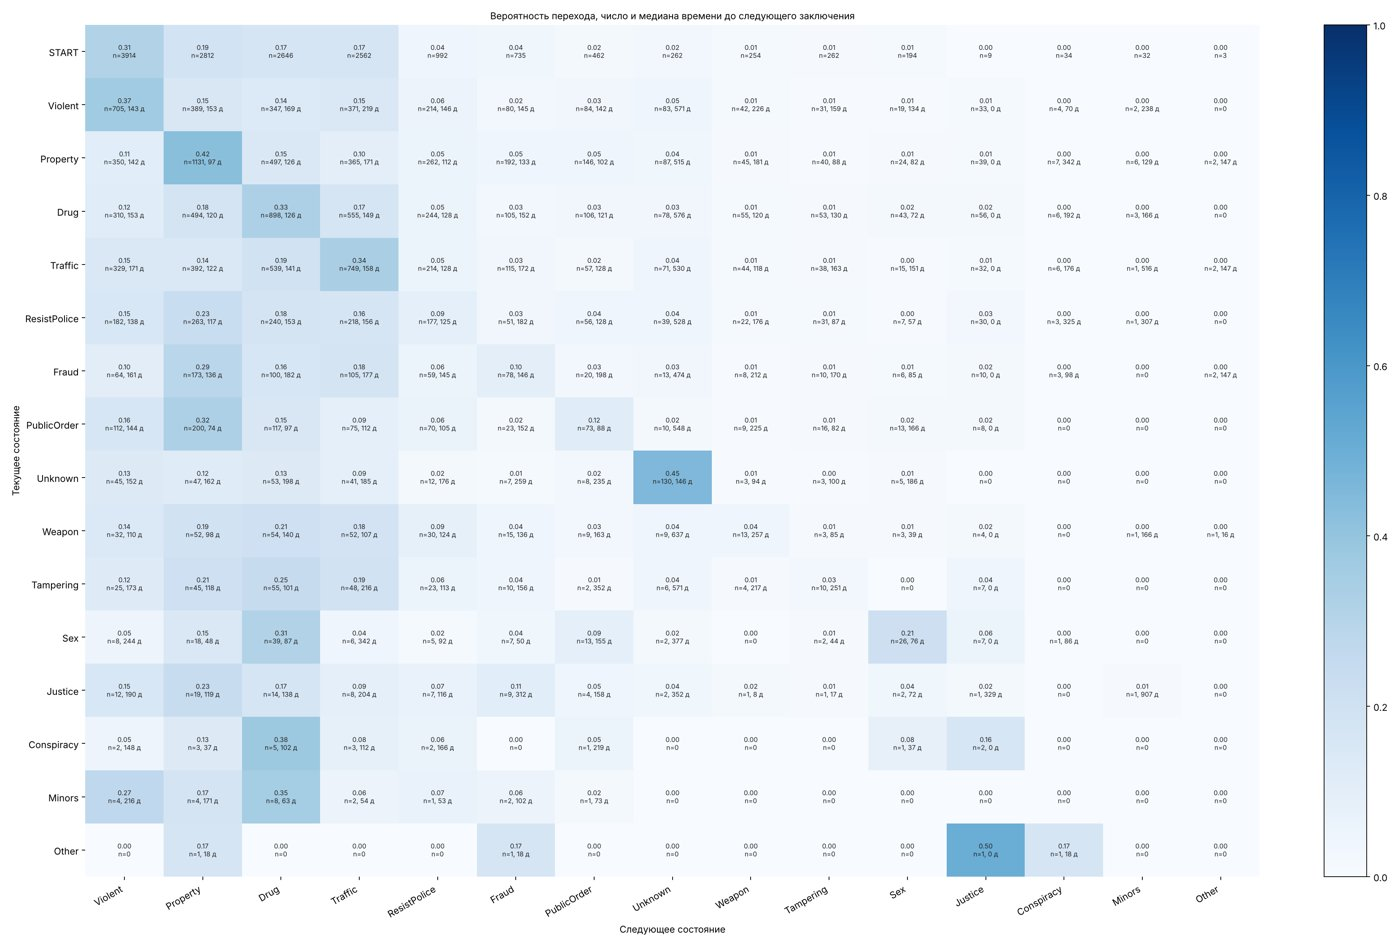

In [15]:
med = arcs.set_index(["from", "to"])["median_days"].to_dict()
base.plot_matrix(probs, raw_pairs.drop(columns="CENSORED"), OUT / "transition_matrix.png", med)
show(OUT / "transition_matrix.png")

**Как читать матрицу.** Строка — текущее состояние, столбец — следующее; в клетке вероятность, число пар `n` и медиана дней до следующего заключения. Диагональ — повтор того же типа (самопереход, петля на графе).

In [16]:
# самопереходы и три самых вероятных перехода из каждого состояния
crime = [s for s in labels if s != OLDCASE]
loops = pd.Series(np.diag(probs.loc[labels, labels]), index=labels)
n_tr = raw_pairs.drop(columns="CENSORED").loc[labels].sum(axis=1)
print(f"средний самопереход по типам преступлений: {loops[crime].mean():.3f}; "
      f"доля самопереходов среди всех переходов (по весу): {np.trace(wcounts.loc[labels, labels].values) / wcounts.loc[labels].values.sum():.3f}")
top3 = (arcs[arcs["from"] != START].sort_values("p", ascending=False).groupby("from").head(3)
        .assign(arc=lambda a: a["to"] + " " + a["p"].map("{:.2f}".format) + " (" + a["median_days"].map("{:.0f}".format) + " д)")
        .groupby("from")["arc"].apply(list).apply(pd.Series))
top3.columns = ["1-й", "2-й", "3-й"][:top3.shape[1]]
top3.insert(0, "самопереход", loops.round(2))
top3.insert(0, "n переходов", n_tr)
top3.sort_values("n переходов", ascending=False)

средний самопереход по типам преступлений: 0.167; доля самопереходов среди всех переходов (по весу): 0.323


,n переходов,самопереход,1-й,2-й,3-й
from,,,,,
Property,3193,0.42,Property 0.42 (97 д),Drug 0.15 (126 д),Violent 0.11 (142 д)
Drug,3006,0.33,Drug 0.33 (126 д),Property 0.17 (120 д),Traffic 0.17 (149 д)
Traffic,2604,0.34,Traffic 0.34 (158 д),Drug 0.19 (141 д),Property 0.14 (122 д)
Violent,2404,0.37,Violent 0.36 (143 д),Property 0.15 (153 д),Traffic 0.15 (219 д)
ResistPolice,1320,0.09,Property 0.23 (117 д),Drug 0.17 (153 д),Traffic 0.17 (156 д)
PublicOrder,726,0.12,Property 0.33 (74 д),Violent 0.16 (144 д),Drug 0.15 (97 д)
Fraud,651,0.10,Property 0.29 (136 д),Traffic 0.17 (177 д),Drug 0.16 (182 д)
Unknown,354,0.45,Unknown 0.45 (146 д),Drug 0.13 (198 д),Violent 0.13 (152 д)
Weapon,278,0.04,Drug 0.21 (140 д),Property 0.19 (98 д),Traffic 0.18 (107 д)


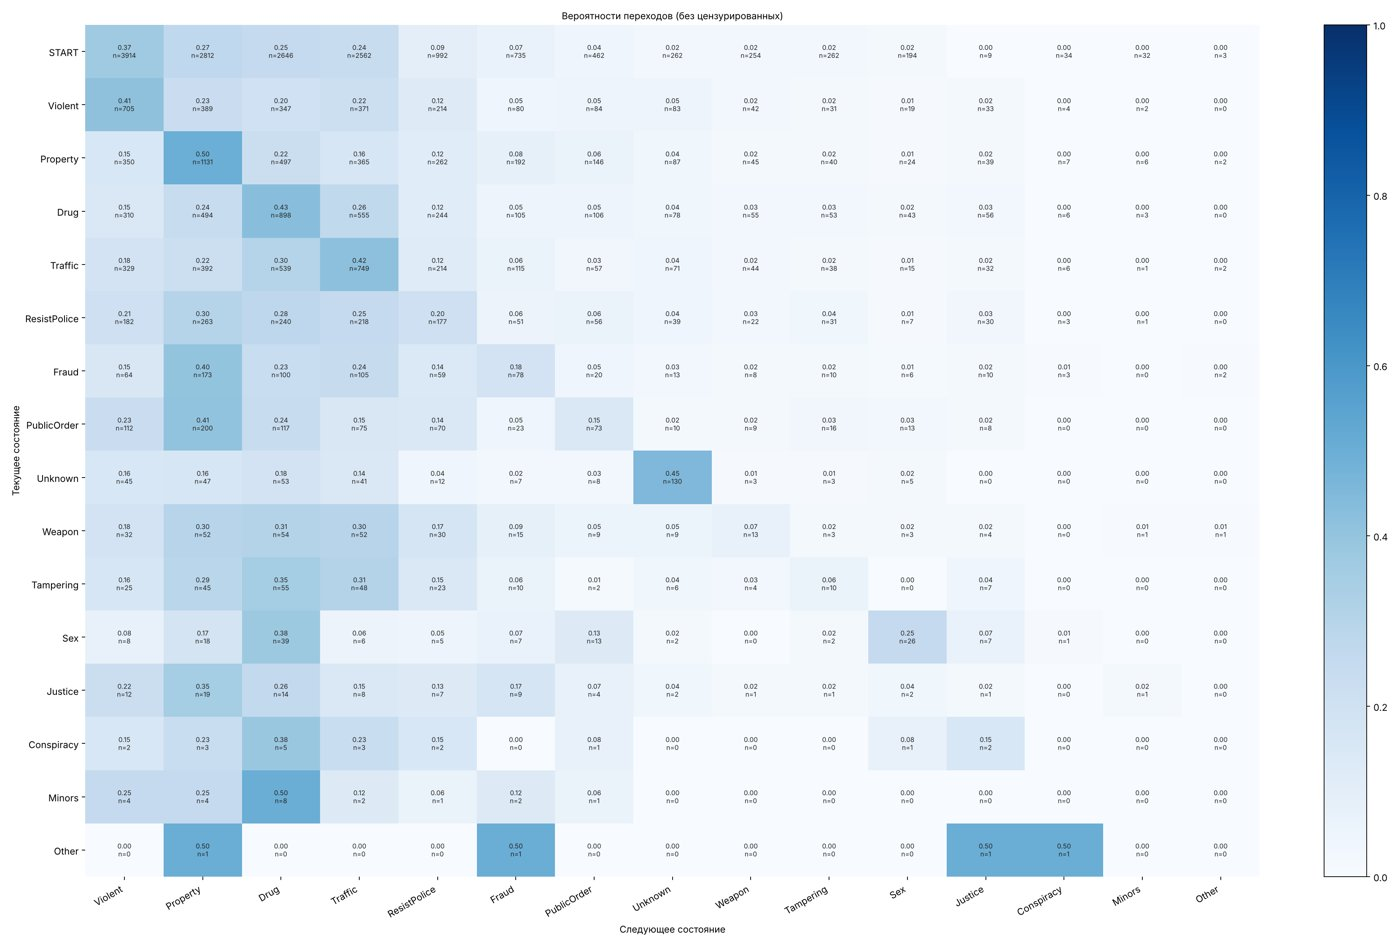

In [17]:
# матрица «следующий эпизод содержит тип» (без весов)
base.plot_matrix(contains.clip(upper=1), raw_pairs.drop(columns="CENSORED"), OUT / "transition_contains.png")
show(OUT / "transition_contains.png")

## Шаг 5. Граф переходов и DFG

### 5.1. Граф переходов
Тот же результат в виде графа: узлы — состояния, дуги с $p \ge$ порога, подпись — вероятность и медиана дней, толщина дуги пропорциональна $p$, самопереходы красные. Рисуется пакетом `graphviz`.

дуг с p >= 0.10: 61 | с p >= 0.05: 86


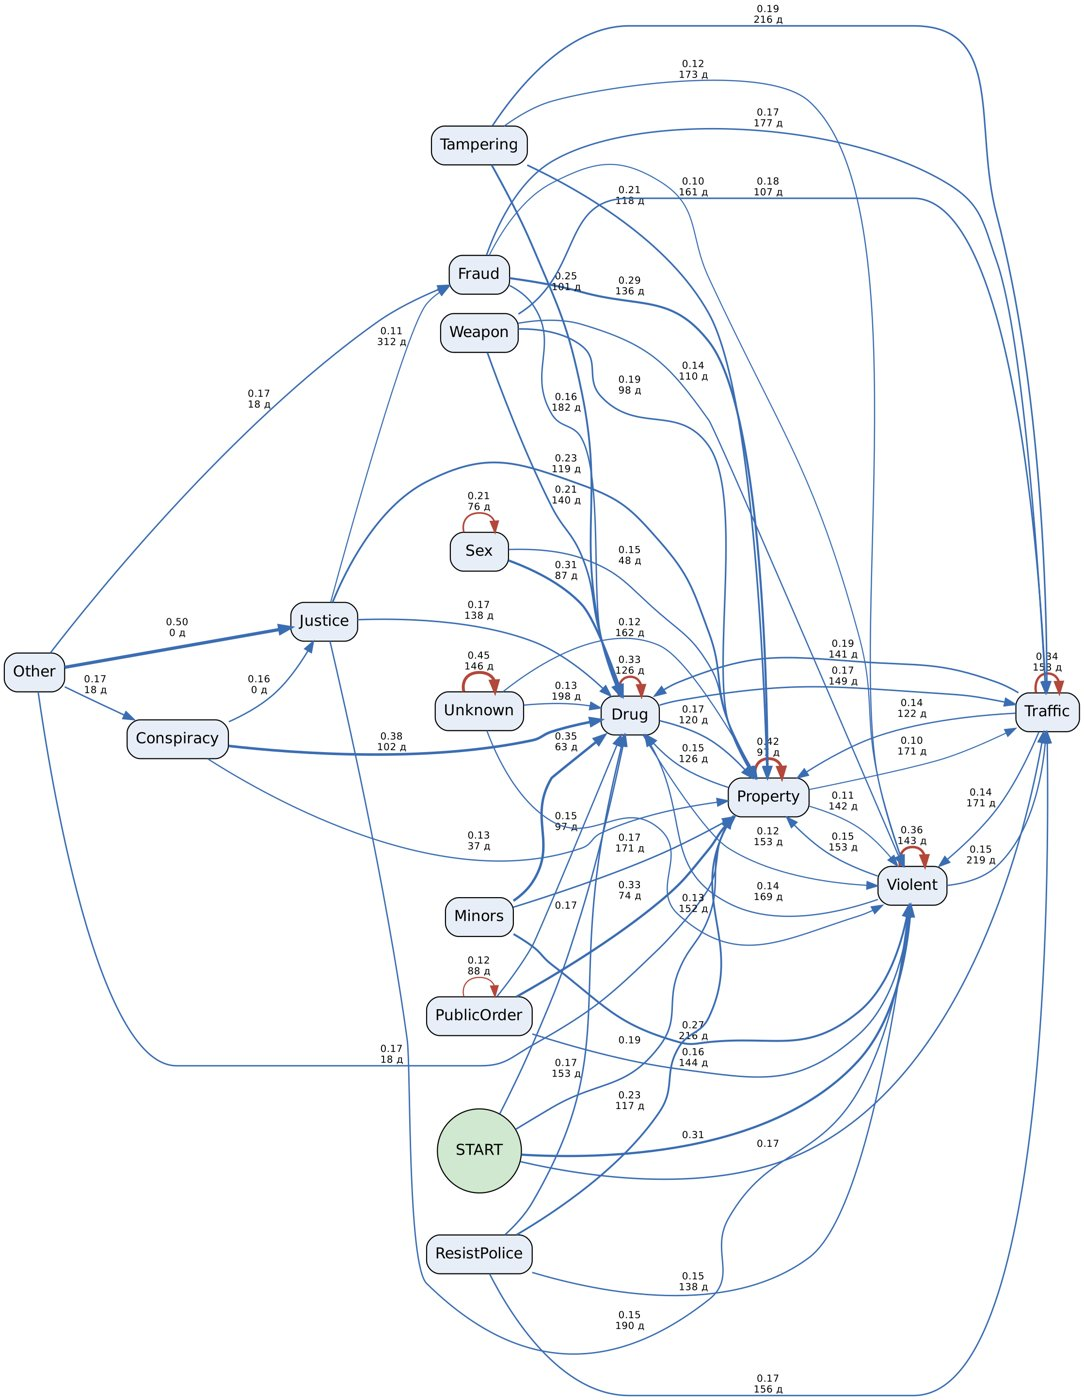

In [18]:
def save_main_graph(arcs, path, min_p=0.05):
    import graphviz
    g = graphviz.Digraph(format="png", graph_attr=dict(rankdir="LR", dpi="160", fontname="Helvetica"),
                         node_attr=dict(shape="box", style="rounded,filled", fillcolor="#e8eef7", fontname="Helvetica"),
                         edge_attr=dict(fontname="Helvetica", fontsize="9"))
    a = arcs[arcs["p"] >= min_p]
    for _, r in a.iterrows():
        lbl = f'{r["p"]:.2f}' + (f'\n{r["median_days"]:.0f} д' if pd.notna(r["median_days"]) else "")
        g.edge(r["from"], r["to"], label=lbl, penwidth=f'{0.5 + 5 * r["p"]:.2f}',
               color="#3b6db3" if r["from"] != r["to"] else "#b3473b")
    g.node(START, shape="circle", fillcolor="#cfe8cf")
    g.render(str(path), cleanup=True)
    return Path(str(path) + ".png")


def graph(min_p, name):
    # нарисовать заново, если есть Graphviz, иначе взять сохранённый рисунок
    if graphviz_ok():
        return save_main_graph(arcs, OUT / name, min_p)
    p = RES / "figures" / f"{name}.png"
    return p if p.exists() else RES / "figures" / "transition_graph_p0.05.png"


print("дуг с p >= 0.10:", int((arcs["p"] >= 0.10).sum()), "| с p >= 0.05:", int((arcs["p"] >= 0.05).sum()))
show(graph(0.10, "transition_graph_p0.10"))

С порогом 0.05 граф подробнее:

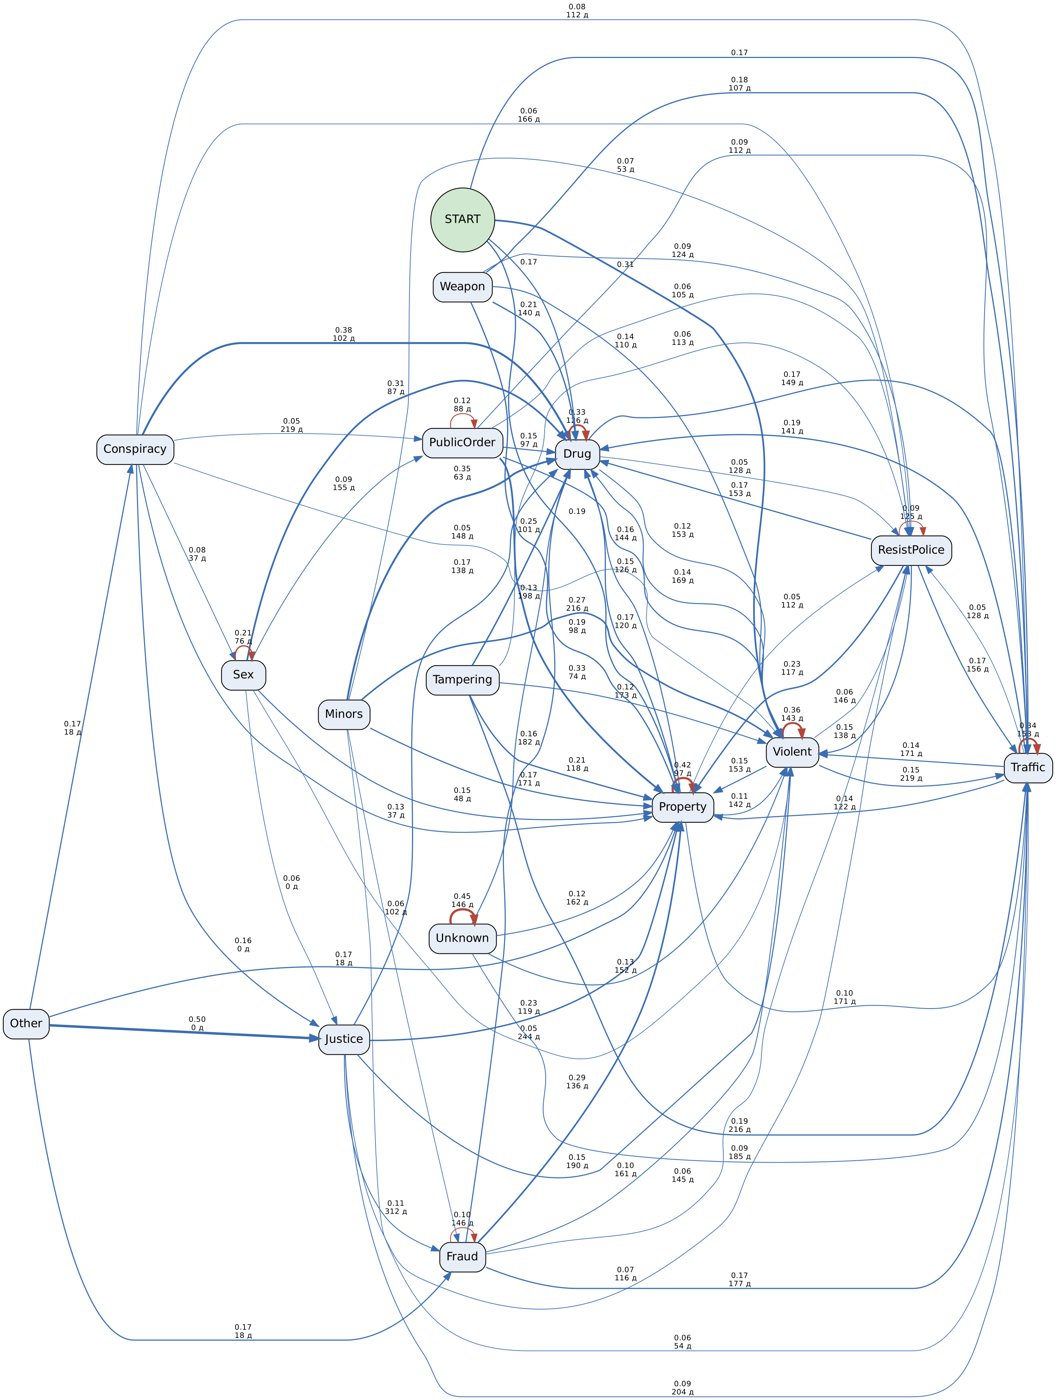

In [19]:
show(graph(0.05, "transition_graph_p0.05"))

In [20]:
# самые частые дуги
arcs.sort_values("n_pairs", ascending=False).head(20)

,from,to,p,p_contains,n_pairs,weight,median_days,q25_days,q75_days
0,START,Violent,0.313,0.370,3914,3311.702,NaN,NaN,NaN
1,START,Property,0.187,0.266,2812,1976.719,NaN,NaN,NaN
2,START,Drug,0.167,0.250,2646,1767.102,NaN,NaN,NaN
3,START,Traffic,0.166,0.242,2562,1759.386,NaN,NaN,NaN
30,Property,Property,0.423,0.498,1131,701.201,97.0,33.00,235.00
4,START,ResistPolice,0.042,0.094,992,439.819,NaN,NaN,NaN
46,Drug,Drug,0.327,0.429,898,462.183,126.0,49.00,292.75
61,Traffic,Traffic,0.337,0.415,749,411.099,158.0,66.00,346.00
5,START,Fraud,0.037,0.069,735,393.869,NaN,NaN,NaN
15,Violent,Violent,0.365,0.411,705,491.690,143.0,56.00,323.00


### 5.2. DFG PM4Py (directly-follows graph)
Стандартная картинка PM4Py по тем же парам эпизодов: на дугах число пар (frequency) или медиана времени (performance). Входящие стрелки — начало (первый эпизод), исходящие — цензурирование (последний эпизод).

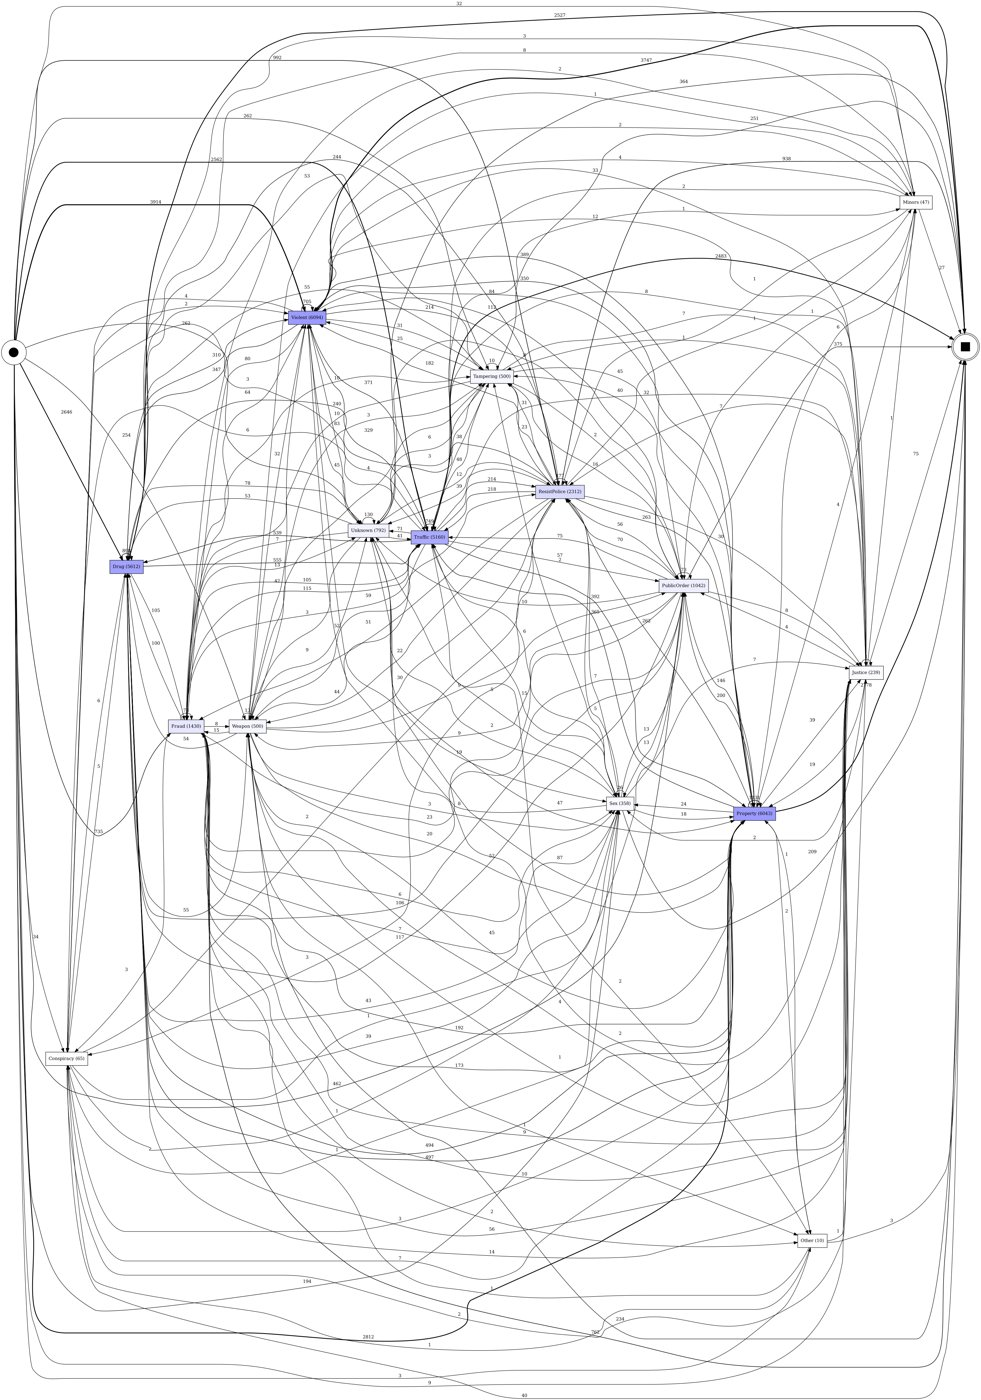

In [21]:
def save_episode_dfg(arcs, df, path, perf_path):
    a = arcs[arcs["from"] != START]
    dfg = {(r["from"], r["to"]): int(r["n_pairs"]) for _, r in a.iterrows()}
    sa = {k: int(v) for k, v in df[df["event_idx"] == 1].explode("types")["types"].value_counts().items()}
    ea = {k: int(v) for k, v in df[df["censored"]].explode("types")["types"].value_counts().items()}
    pm4py.save_vis_dfg(dfg, sa, ea, str(path))
    perf = {(r["from"], r["to"]): float(r["median_days"]) * 86400 for _, r in a.iterrows() if pd.notna(r["median_days"])}
    pm4py.save_vis_performance_dfg(perf, sa, ea, str(perf_path))


FIGS = OUT if graphviz_ok() else RES / "figures"
if graphviz_ok():
    save_episode_dfg(arcs, df, OUT / "dfg_frequency.png", OUT / "dfg_performance.png")
show(FIGS / "dfg_frequency.png", width=1100)

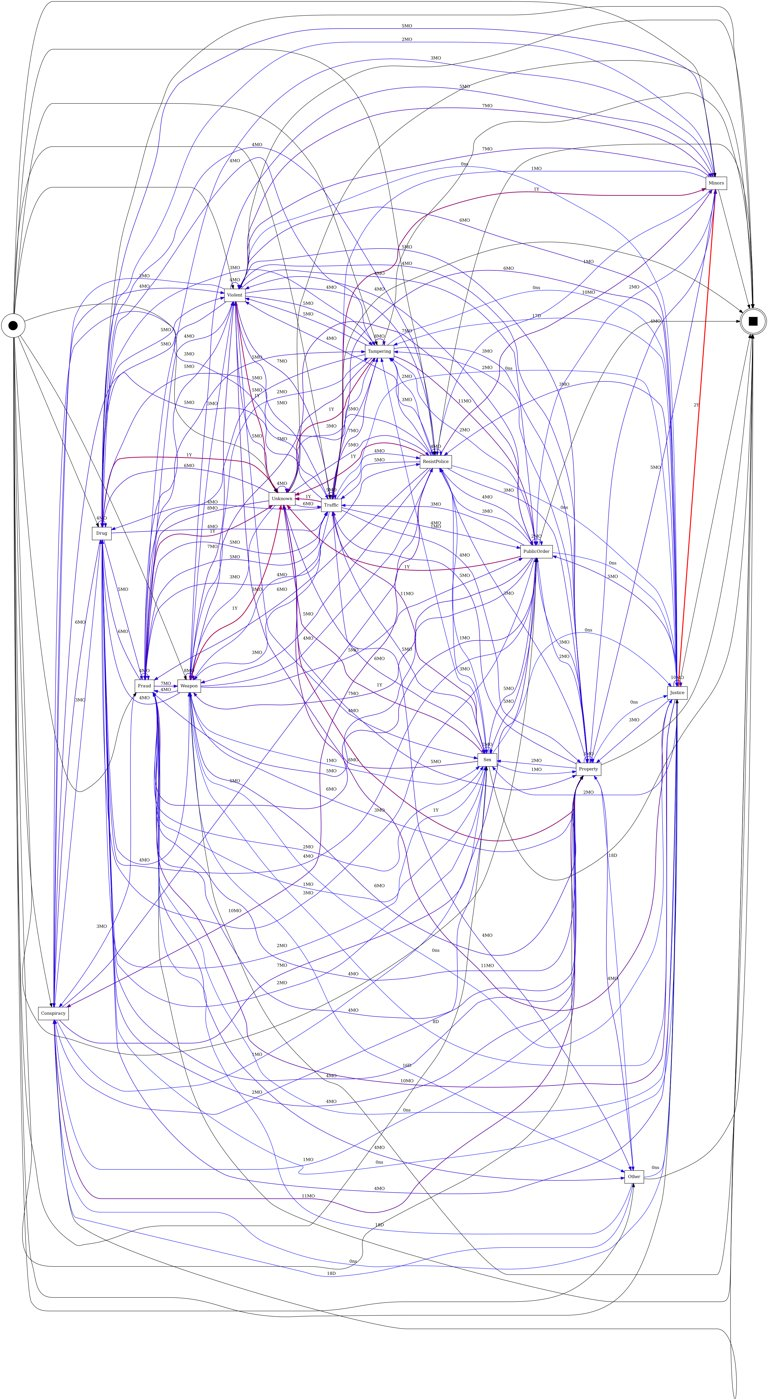

In [22]:
show(FIGS / "dfg_performance.png", width=1100)

## Шаг 6. Развилки (несколько типов в одном эпизоде)

Какие типы встречаются вместе. В матрице совместной встречаемости строка $a$, столбец $b$ — доля эпизодов с $a$, в которых есть и $b$. `share_alone` — доля эпизодов с типом, где он единственный.

In [23]:
def fork_tables(df, labels):
    n = df["n_types"].value_counts().sort_index()
    combos = df.loc[df["n_types"] > 1, "combo"].value_counts()
    combos = pd.DataFrame({"episodes": combos, "share_of_multi": (combos / combos.sum()).round(3)})
    e = df[["ep_row", "types"]].explode("types")
    m = e.merge(e, on="ep_row")
    co = pd.crosstab(m["types_x"], m["types_y"]).reindex(index=labels, columns=labels, fill_value=0)
    co_p = co.div(np.diag(co), axis=0)
    alone = df[df["n_types"] == 1].explode("types")["types"].value_counts()
    tot = e["types"].value_counts()
    solo = pd.DataFrame({"episodes_with_type": tot, "alone": alone.reindex(tot.index, fill_value=0)})
    solo["share_alone"] = (solo["alone"] / solo["episodes_with_type"]).round(3)
    return n, combos, co, co_p, solo


n_types, combos, co, co_p, solo = fork_tables(df, labels)
display(n_types.rename("шагов").to_frame().T)
display(combos.head(12))
solo

n_types,1,2,3,4,5,6,7
шагов,11981,4351,1106,255,46,6,2


,episodes,share_of_multi
combo,,
Drug+Traffic,1041,0.181
Fraud+Property,491,0.085
Property+Violent,350,0.061
Property+ResistPolice,292,0.051
Drug+Property,268,0.046
ResistPolice+Violent,246,0.043
Property+Traffic,185,0.032
ResistPolice+Traffic,136,0.024
Drug+Violent,136,0.024


,episodes_with_type,alone,share_alone
types,,,
Violent,5462,3812,0.698
Property,5048,2550,0.505
Drug,4622,1988,0.430
Traffic,4287,1934,0.451
ResistPolice,1809,153,0.085
Fraud,1193,224,0.188
PublicOrder,868,267,0.308
Unknown,653,653,1.000
Weapon,410,71,0.173


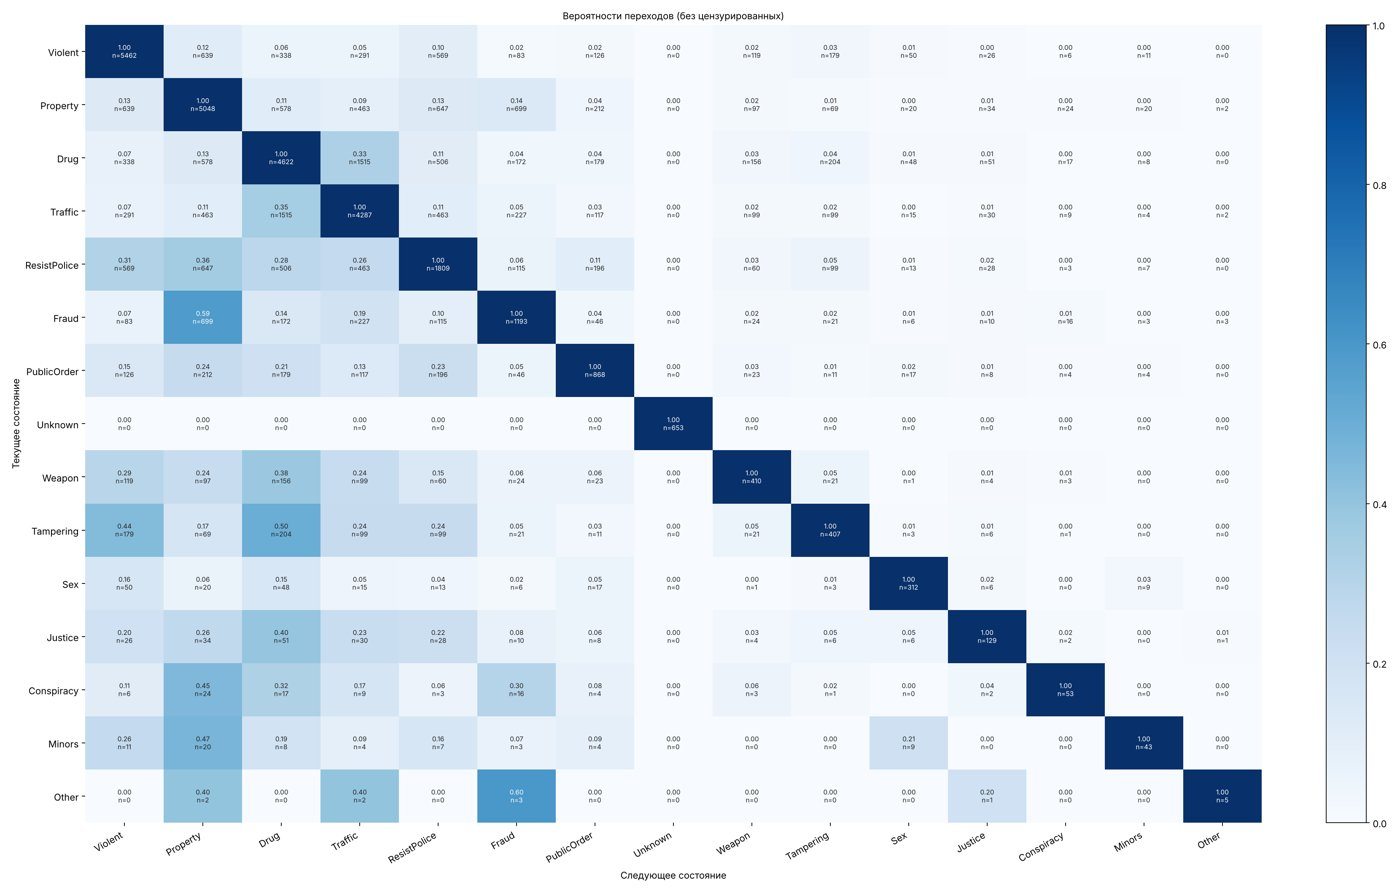

In [24]:
base.plot_matrix(co_p, co, OUT / "fork_cooccurrence.png")
show(OUT / "fork_cooccurrence.png")

## Шаг 7. От чего зависит следующее состояние

Для каждой пары (текущий тип → следующий тип) берутся признаки текущего эпизода: пол, возраст, раса, класс обвинения (Felony / Misdemeanor), длительность заключения, интервал до предыдущего, номер события, число типов, предыдущая комбинация.
- **V Крамера** — сила связи признака со следующим состоянием, отдельно для каждого текущего состояния (0 — нет связи, 1 — полная);
- **дерево решений** (глубина 4) предсказывает следующий тип по всем признакам сразу; важность признака = вклад в разбиения.

In [25]:
from sklearn.tree import DecisionTreeClassifier, export_text


def transition_drivers(df, labels):
    d, _ = pair_rows(df)
    feats = ["sex", "age_group", "race", "charge_class", "dur_class", "gap_prev_bin", "event_idx_bin",
             "n_types_bin", "prev_combo"]
    d["gap_prev_bin"] = pd.cut(d["gap_prev"].fillna(-1), [-np.inf, -0.5, 30, 180, 365, np.inf],
                               labels=["first", "<=30d", "31-180d", "181-365d", ">365d"]).astype(str)
    d["event_idx_bin"] = d["event_idx"].clip(upper=4).astype(str).replace("4", "4+")
    d["n_types_bin"] = d["n_types"].clip(upper=3).astype(str).replace("3", "3+")
    rows = []
    for src in labels:
        sub = d[d["src"] == src]
        for f in feats:
            ct = pd.crosstab(sub[f], sub["dst"], values=sub["w"], aggfunc="sum").fillna(0)
            ct = ct.loc[ct.sum(axis=1) >= 20]
            ct = ct.loc[:, ct.sum(axis=0) > 0]
            if ct.shape[0] < 2 or ct.shape[1] < 2:
                continue
            v, p = base.cramers_v(ct)
            rows.append(dict(from_state=src, feature=f, n=round(ct.values.sum(), 1), cramers_v=round(v, 3), p_value=p))
    assoc = pd.DataFrame(rows).sort_values(["from_state", "cramers_v"], ascending=[True, False])
    prof = []
    for f in feats:
        g = pd.crosstab(d[f], d["dst"], values=d["w"], aggfunc="sum", normalize="index").fillna(0)
        g = g.reindex(columns=labels, fill_value=0)
        g.insert(0, "n", d.groupby(f)["w"].sum().round(1))
        g.index = [f"{f}={i}" for i in g.index]
        prof.append(g.round(3))
    profile = pd.concat(prof)
    X = pd.get_dummies(d[["src"] + feats].astype(str), drop_first=False)
    tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, random_state=SEED,
                                  class_weight="balanced").fit(X, d["dst"], sample_weight=d["w"])
    imp = pd.Series(tree.feature_importances_, index=X.columns)
    imp = imp.groupby(lambda c: next(f for f in ["src"] + feats if c.startswith(f + "_"))).sum()
    return assoc, profile, imp.sort_values(ascending=False).round(3), export_text(tree, feature_names=list(X.columns))


assoc, profile, imp, tree_txt = transition_drivers(df, labels)
assoc.to_csv(OUT / "drivers_cramers_v.csv", index=False)
saved_imp = pd.read_csv(RES / "tables" / "drivers_tree_importance.csv", index_col=0)["importance"]
pd.DataFrame({"важность": imp, "сохранено": saved_imp})

,важность,сохранено
src,0.648,0.648
sex,0.127,0.127
dur_class,0.125,0.125
n_types_bin,0.071,0.071
prev_combo,0.029,0.029
age_group,0.000,0.000
charge_class,0.000,0.000
event_idx_bin,0.000,0.000
gap_prev_bin,0.000,0.000
race,0.000,0.000


In [26]:
# самые сильные связи (V Крамера >= 0.15 при n >= 100)
assoc[(assoc["n"] >= 100) & (assoc["cramers_v"] >= 0.15)].sort_values("cramers_v", ascending=False).head(15)

,from_state,feature,n,cramers_v,p_value
69,Unknown,prev_combo,241.0,0.419,6.775263e-06
68,Unknown,event_idx_bin,270.0,0.257,1.717250e-02
62,PublicOrder,prev_combo,213.0,0.248,2.470219e-01
49,Fraud,dur_class,215.8,0.239,5.437432e-01
65,Unknown,race,261.0,0.205,3.559494e-01
67,Unknown,gap_prev_bin,279.0,0.202,2.772623e-01
60,PublicOrder,event_idx_bin,313.9,0.196,3.224871e-01
46,Fraud,age_group,226.3,0.195,9.467723e-01
59,PublicOrder,gap_prev_bin,301.2,0.189,4.961208e-01
63,Unknown,sex,289.0,0.188,4.250871e-01


In [27]:
print(tree_txt[:3000])

|--- src_Unknown <= 0.50
|   |--- src_Sex <= 0.50
|   |   |--- sex_Female <= 0.50
|   |   |   |--- n_types_bin_3+ <= 0.50
|   |   |   |   |--- class: Violent
|   |   |   |--- n_types_bin_3+ >  0.50
|   |   |   |   |--- class: Justice
|   |   |--- sex_Female >  0.50
|   |   |   |--- dur_class_S1_<=1d <= 0.50
|   |   |   |   |--- class: Sex
|   |   |   |--- dur_class_S1_<=1d >  0.50
|   |   |   |   |--- class: Minors
|   |--- src_Sex >  0.50
|   |   |--- class: Sex
|--- src_Unknown >  0.50
|   |--- prev_combo_first <= 0.50
|   |   |--- class: Unknown
|   |--- prev_combo_first >  0.50
|   |   |--- class: Unknown



## Шаг 8. Модели процесса: Inductive Miner, Heuristics Miner, DFG

Модели учатся на журнале 80% людей (`train`), проверяются на 20% (`test`), разбиение по людям (`GroupShuffleSplit`, seed 42).
- **Inductive Miner (IM)**, порог шума 0 / 0.2 / 0.5 — всегда даёт корректную (sound) сеть Петри, но с развилками превращается в «параллельный блок независимых циклов»;
- **Heuristics Miner (HM)**, порог зависимости 0.5 / 0.9 — связи по частоте directly-follows;
- **DFG с фильтром** — дуги с долей ≥ 5 / 10 / 20% от исходящих из узла, переведённые в сеть Петри.

Метрики качества: **fitness** (насколько журнал теста воспроизводится моделью: token replay и alignments), **precision** ETC (насколько модель не разрешает лишнего), `lost_occ_share` — доля переходов теста, которых модель не допускает, `extra_edges` — лишние допускаемые переходы.

In [28]:
from sklearn.model_selection import GroupShuffleSplit

cases = log["case:concept:name"].unique()
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(cases, groups=cases))
train_log = log[log["case:concept:name"].isin(set(cases[tr_idx]))]
test_log = log[log["case:concept:name"].isin(set(cases[te_idx]))]
print(f"train: {train_log['case:concept:name'].nunique():,} людей, test: {test_log['case:concept:name'].nunique():,} людей")

models = {}
if RUN_MODELS:
    t0 = time.time()
    for nt in [0.0, 0.2, 0.5]:
        models[f"IM_noise{nt}"] = pm4py.discover_petri_net_inductive(train_log, noise_threshold=nt)
    for dep in [0.5, 0.9]:
        models[f"HM_dep{dep}"] = pm4py.discover_petri_net_heuristics(train_log, dependency_threshold=dep)
    dfg_tr, sa_tr, ea_tr = pm4py.discover_dfg(train_log)
    out_tot = pd.Series(dfg_tr).groupby(level=0).sum()
    sa_tot = sum(sa_tr.values())
    for thr in [0.05, 0.10, 0.20]:
        dfg_f = {k: v for k, v in dfg_tr.items() if v / out_tot[k[0]] >= thr}
        sa_f = {k: v for k, v in sa_tr.items() if v / sa_tot >= thr}
        models[f"DFG_p>={thr}"] = pm4py.convert_to_petri_net(dfg_f, sa_f, ea_tr)
    print(f"моделей: {len(models)}, {time.time() - t0:.0f} с")
    display(pd.DataFrame({k: dict(places=len(n.places), transitions=len(n.transitions),
                                  silent=sum(t.label is None for t in n.transitions)) for k, (n, i, f) in models.items()}).T)

train: 8,464 людей, test: 2,116 людей


моделей: 8, 1 с


,places,transitions,silent
IM_noise0.0,68,91,76
IM_noise0.2,47,69,54
IM_noise0.5,46,60,45
HM_dep0.5,35,157,142
HM_dep0.9,31,147,132
DFG_p>=0.05,17,96,14
DFG_p>=0.1,17,78,14
DFG_p>=0.2,17,36,14


### 8.1. Качество моделей на тесте

Пересчёт всех моделей занимает часы (выравнивания для IM с 15 состояниями не считались вообще), поэтому таблица берётся из сохранённого `model_quality.csv`. Флаг `RUN_EVAL = True` пересчитает метрики для HM dep 0.9 и покажет их рядом.

In [29]:
quality = pd.read_csv(RES / "tables" / "model_quality.csv")
cols = [c for c in ["model", "fitness_tbr", "fitness_align", "precision_etc", "f1", "lost_edges", "lost_occ_share",
                    "extra_edges", "places", "transitions", "silent"] if c in quality.columns]
quality[quality["split"] == "test"][cols].reset_index(drop=True)

,model,fitness_tbr,fitness_align,precision_etc,f1,lost_edges,lost_occ_share,extra_edges,places,transitions,silent
0,IM_noise0.0,0.9999,NaN,0.6248,0.7690,0,0.0000,74,68,91,76
1,IM_noise0.2,0.9638,NaN,0.8473,0.9018,72,0.1687,28,47,69,54
2,IM_noise0.5,0.8728,NaN,0.7059,0.7805,45,0.0337,35,46,60,45
3,HM_dep0.5,0.9941,0.9879,0.6995,0.8212,0,0.0000,88,35,157,142
4,HM_dep0.9,0.9949,0.9897,0.6979,0.8203,40,0.0159,7,31,147,132
5,DFG_p>=0.05,0.9434,0.8886,0.8541,0.8966,110,0.1838,0,17,96,14
6,DFG_p>=0.1,0.9171,0.8512,0.9108,0.9139,123,0.2527,0,17,78,14
7,DFG_p>=0.2,0.7163,0.2884,0.9834,0.8289,150,0.8463,0,17,36,14


In [30]:
if RUN_EVAL and RUN_MODELS:
    t0 = time.time()
    q, edges = base.evaluate({"HM_dep0.9": models["HM_dep0.9"]}, train_log, test_log, max_states=300_000)
    print(f"{time.time() - t0:.0f} с")
    display(q[q["split"] == "test"][cols])
else:
    print("RUN_EVAL = False: пересчёт пропущен")

RUN_EVAL = False: пересчёт пропущен


### 8.2. Heuristics Miner (dep 0.9): сеть Петри и heuristics net

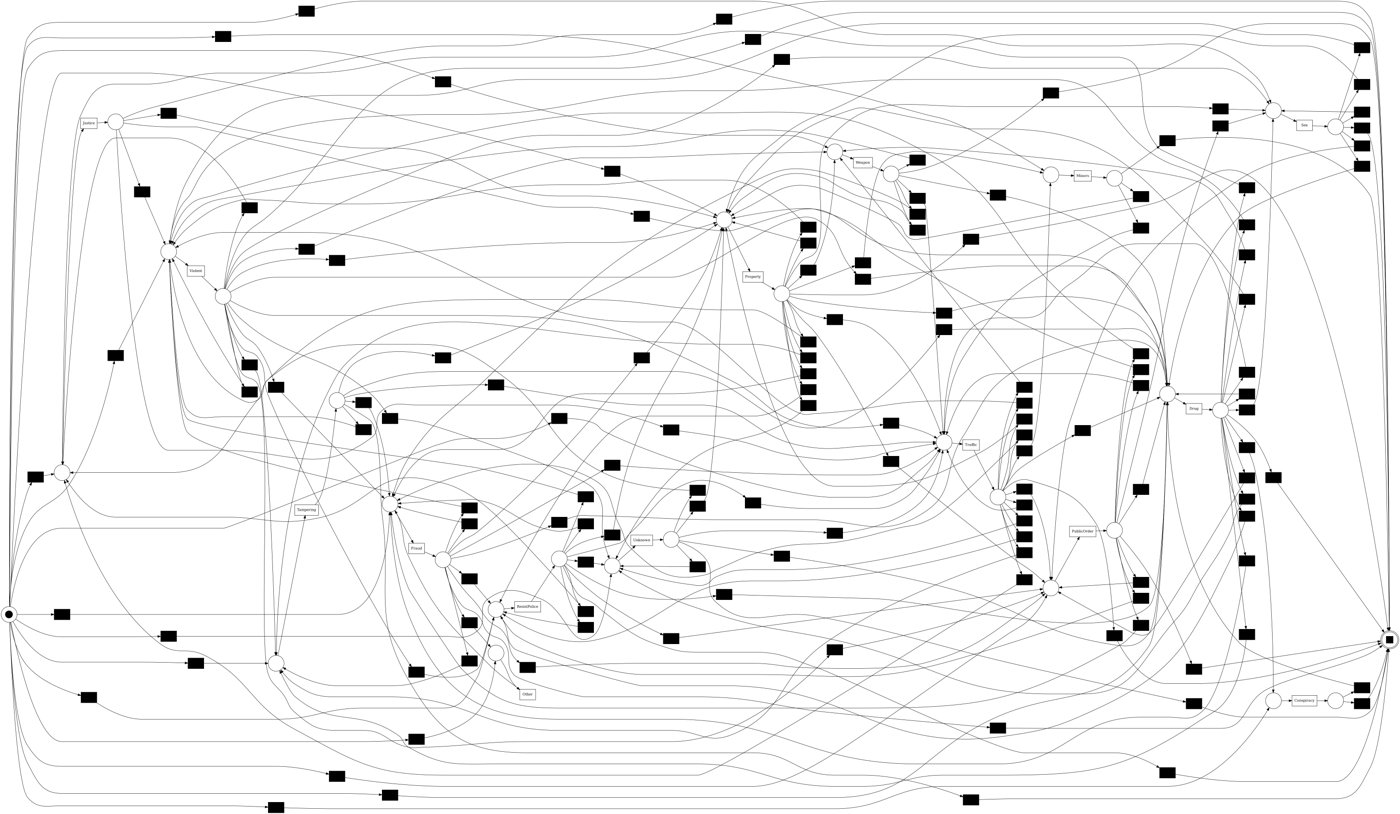

In [31]:
def petri_png(name):
    path = OUT / f"petri_{name}.png"
    if RUN_MODELS and graphviz_ok():
        pm4py.save_vis_petri_net(*models[name], str(path))
        return path
    return RES / "figures" / f"petri_{name}.png"


show(petri_png("HM_dep0.9"), width=1200)

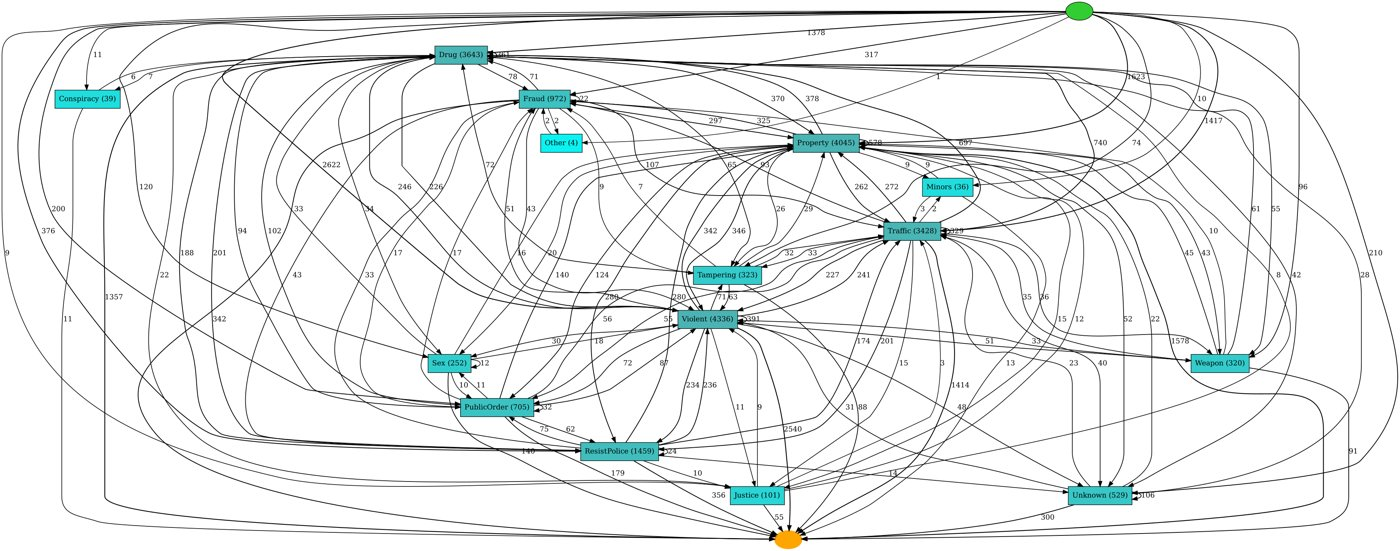

In [32]:
# на дугах heuristics net — число directly-follows и зависимость
if RUN_MODELS and graphviz_ok():
    pm4py.save_vis_heuristics_net(pm4py.discover_heuristics_net(train_log, dependency_threshold=0.9),
                                  str(OUT / "heuristics_net_dep0.9.png"))
    show(OUT / "heuristics_net_dep0.9.png", width=1200)
else:
    show(RES / "figures" / "heuristics_net_dep0.9.png", width=1200)

### 8.3. Inductive Miner (noise 0.2): дерево процесса и сеть Петри

Дерево показывает, почему IM здесь мало информативен: состояния собираются в параллельный блок (`+`) независимых циклов (`*`), то есть модель почти не различает, из какого типа в какой переходят.

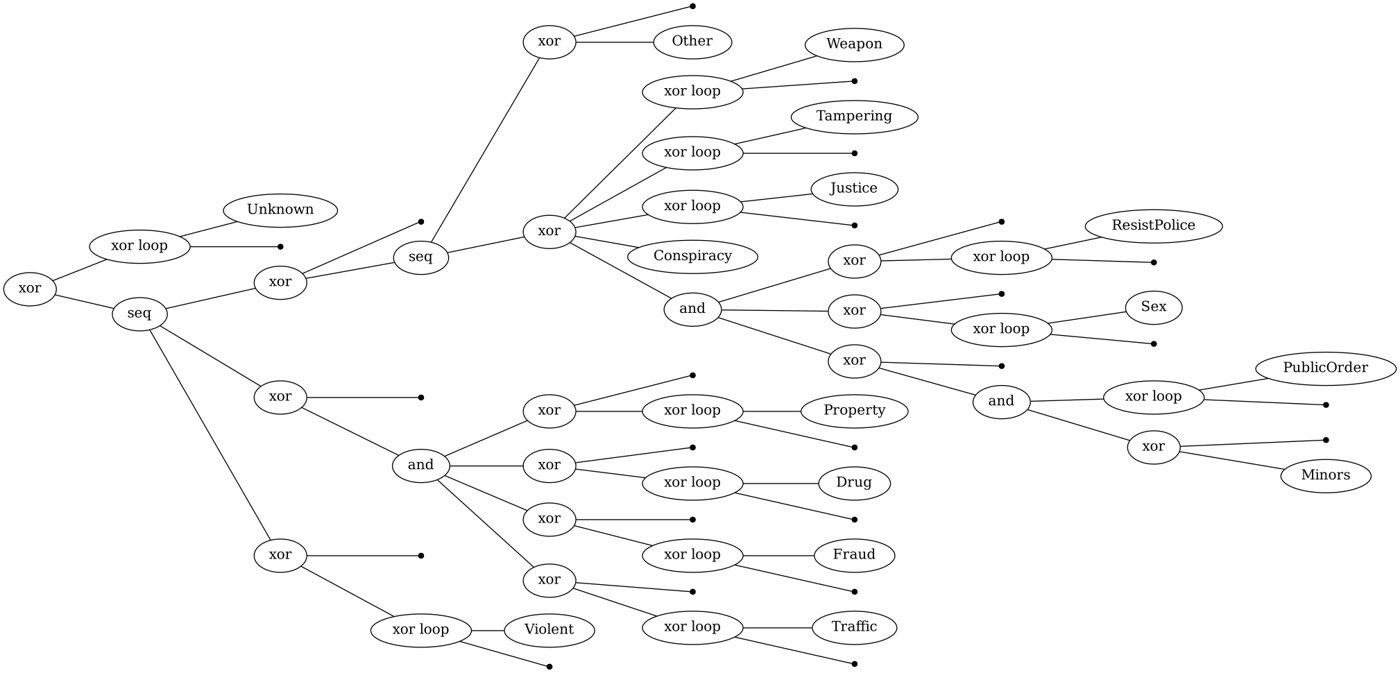

In [33]:
if RUN_MODELS and graphviz_ok():
    pm4py.save_vis_process_tree(pm4py.discover_process_tree_inductive(train_log, noise_threshold=0.2),
                                str(OUT / "process_tree_IM_noise0.2.png"))
    show(OUT / "process_tree_IM_noise0.2.png", width=1100)
else:
    show(RES / "figures" / "process_tree_IM_noise0.2.png", width=1100)

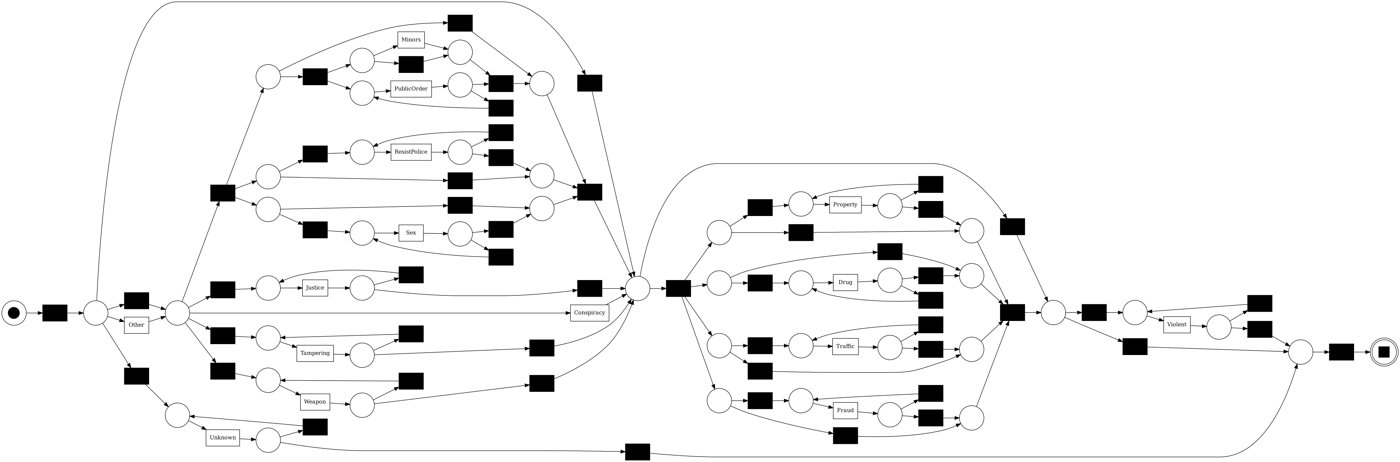

In [34]:
show(petri_png("IM_noise0.2"), width=1200)

## Шаг 9. Сравнение с другими вариантами

Берутся сохранённые результаты соседних папок `stage1/…` (если они есть рядом): число эпизодов и переходов, доля развилок, средний самопереход по типам преступлений (без `OldCase`) и качество HM dep 0.9 на тесте.

In [35]:
OTHERS = {"все новые": "all_new/results", "OldCase": "oldcase/results",
          "без OldCase": "no_oldcase/results", "склейка, все новые": "glue7/results_glue_all",
          "склейка, без OldCase": "glue7/results_glue_noold"}
rows = {}
for name, rel in OTHERS.items():
    r = HERE / ".." / rel
    if not (r / "tables" / "log_info.csv").exists():
        continue
    li = pd.read_csv(r / "tables" / "log_info.csv", index_col=0)["value"]
    pr = pd.read_csv(r / "tables" / "transition_probs.csv", index_col=0)
    tps = [c for c in pr.columns if c != OLDCASE and c in pr.index]
    mq = pd.read_csv(r / "tables" / "model_quality.csv")
    hm = mq[(mq["model"] == "HM_dep0.9") & (mq["split"] == "test")].iloc[0]
    rows[name] = {"эпизодов": int(li["episodes"]), "шагов": int(li["steps"]),
                  "переходов": int(li["transitions_observed"]), "людей с повторами": int(li["people_repeat"]),
                  "доля развилок": float(li["share_multi_type"]),
                  "средний самопереход": round(float(np.mean([pr.loc[s, s] for s in tps])), 3),
                  "HM 0.9 fitness": round(float(hm["fitness_tbr"]), 3), "HM 0.9 precision": round(float(hm["precision_etc"]), 3)}
cmp = pd.DataFrame.from_dict(rows, orient="index")
cmp

,эпизодов,шагов,переходов,людей с повторами,доля развилок,средний самопереход,HM 0.9 fitness,HM 0.9 precision
все новые,21716,21866,11286,5230,0.376,0.328,0.998,0.572
OldCase,21716,21817,11237,5230,0.264,0.120,0.995,0.675
без OldCase,17646,17747,7167,4053,0.325,0.167,0.995,0.698
"склейка, все новые",21470,21618,11038,5199,0.376,0.326,0.998,0.567
"склейка, без OldCase",17525,17626,7046,4028,0.326,0.165,0.996,0.695


**Как читать.** «Все новые» и OldCase имеют одинаковое число эпизодов; OldCase переносит повторы старых дел из самопереходов в отдельное состояние. «Без OldCase» убирает эти эпизоды совсем: переходов меньше, самопереходов примерно вдвое меньше, precision HM выше. Склейка ±7 дней почти ничего не меняет (склеивается около 1% эпизодов): возвраты по старому делу не быстрые, поэтому временное окно не заменяет правило по `case_number`.

## Шаг 10. Итог и файлы

Сверка с сохранёнными результатами (шаги 2–4) и список того, что ноутбук записал в `notebook_out/`.

In [36]:
print("log_info совпадает:          ", bool(chk["совпадает"].all()))
print("журнал событий совпадает:    ", bool(same))
print("transition_probs |разница|:  ", float(diff))
sorted(p.name for p in OUT.iterdir())

log_info совпадает:           True
журнал событий совпадает:     True
transition_probs |разница|:   0.0


['dfg_frequency.png',
 'dfg_performance.png',
 'drivers_cramers_v.csv',
 'event_log.csv',
 'event_table.csv',
 'fork_cooccurrence.png',
 'heuristics_net_dep0.9.png',
 'log_info.csv',
 'petri_HM_dep0.9.png',
 'petri_IM_noise0.2.png',
 'process_tree_IM_noise0.2.png',
 'transition_arcs.csv',
 'transition_contains.csv',
 'transition_contains.png',
 'transition_graph_p0.05.png',
 'transition_graph_p0.10.png',
 'transition_matrix.png',
 'transition_pair_counts.csv',
 'transition_probs.csv']